# 04 - Evaluate and gate

Scores the model against the held-out test split, logs the metrics into the
**same** MLflow run as the training job, and records a pass/fail against
`evaluate.auc_threshold`.

One run = one model = one set of metrics. The original workshop opened a separate
nested run for evaluation, which meant AUC and hyperparameters lived in different
places.

In [1]:
import json
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
os.environ["CHURN_PROJECT_ROOT"] = str(PROJECT_ROOT)

# Put this kernel's venv bin/ first on PATH so shell commands (dvc, ...) resolve to the
# venv, however Jupyter was launched.
import sys
os.environ["PATH"] = f"{Path(sys.executable).parent}{os.pathsep}{os.environ['PATH']}"
for line in (PROJECT_ROOT / ".env").read_text().strip().splitlines():
    key, _, value = line.partition("=")
    os.environ[key] = value

from churn.config import Settings, load_params

params = load_params()
settings = Settings.load(params)
print("region:", settings.region, "| bucket:", settings.bucket)

region: us-east-1 | bucket: sagemaker-us-east-1-063676201336


In [2]:
handles = json.loads(Path("reports/train_result.json").read_text())
print(json.dumps(handles, indent=2))

{
  "run_id": "0eb9b0c6f641470abae33de9b38e890a",
  "training_job_name": "player-churn-xgb-2026-10-28-15-53-18-548",
  "model_data": "s3://sagemaker-us-east-1-063676201336/player-churn/dvc-mlflow/runs/20261028-155311/output/player-churn-xgb-2026-10-28-15-53-18-548/output/model.tar.gz",
  "metrics": {
    "validation_auc": 0.99372,
    "train_auc": 1.0
  }
}


## 1. Score

The test split is the one produced in notebook 02 — stratified, **not**
rebalanced, no players shared with train.

In [3]:
from churn.evaluation import evaluate

result = evaluate(
    run_id=handles["run_id"],
    model_data=handles["model_data"],
    settings=settings,
    params=params,
)

for key, value in sorted(result.metrics.items()):
    print(f"  {key:26s} {value:.4f}")

/Users/ritabanchowdhury/.venvs/churn-mlops/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sagemaker.config INFO - Not applying SDK defaults from location: /usr/local/share/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/ritabanchowdhury/Library/Application Support/sagemaker/config.yaml


/Users/ritabanchowdhury/.venvs/churn-mlops/lib/python3.11/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
Matplotlib is building the font cache; this may take a moment.


🏃 View run train-20261028-155311 at: https://us-east-1.experiments.sagemaker.aws/#/experiments/1/runs/0eb9b0c6f641470abae33de9b38e890a
🧪 View experiment at: https://us-east-1.experiments.sagemaker.aws/#/experiments/1
  test_accuracy              0.9695
  test_auc                   0.9671
  test_average_precision     0.8641
  test_f1                    0.8148
  test_positive_rate         0.0854
  test_precision             0.8462
  test_recall                0.7857
  test_rows                  164.0000


In [4]:
verdict = "PASS" if result.passed else "FAIL"
print(f"test AUC {result.auc:.4f}  vs gate {result.threshold:.2f}  ->  {verdict}")

test AUC 0.9671  vs gate 0.75  ->  PASS


### On the AUC number

Expect it to be **lower than the ~0.99 the original workshop reported**, and that
is the point.

The workshop oversampled before splitting, so its test fold contained duplicates
of training rows and had been rebalanced to 50/50. It was scoring memorisation on
a synthetic distribution. This test fold has the real 8.4% churn rate and shares
no players with train.

Because of that class imbalance, also read `test_average_precision` — average
precision is far more informative than AUC when positives are rare, and
`test_precision`/`test_recall` at the default 0.5 threshold tell you whether the
model is usable at all.

In [5]:
import pandas as pd

print("metrics worth more than AUC here:")
print(pd.Series({
    "average_precision": result.metrics["test_average_precision"],
    "precision@0.5": result.metrics["test_precision"],
    "recall@0.5": result.metrics["test_recall"],
    "f1@0.5": result.metrics["test_f1"],
    "positive_rate": result.metrics["test_positive_rate"],
}).round(4).to_string())

metrics worth more than AUC here:
average_precision    0.8641
precision@0.5        0.8462
recall@0.5           0.7857
f1@0.5               0.8148
positive_rate        0.0854


## 2. The ROC curve and prediction baseline

Both are logged as run artifacts. `prediction_baseline.csv` is kept for
model-quality monitoring later: it is the reference distribution a Model Monitor
job compares live traffic against.

In [6]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
client = MlflowClient()
for artifact in client.list_artifacts(result.run_id):
    print(" ", artifact.path)

  evaluation.json
  prediction_baseline.csv
  roc.png


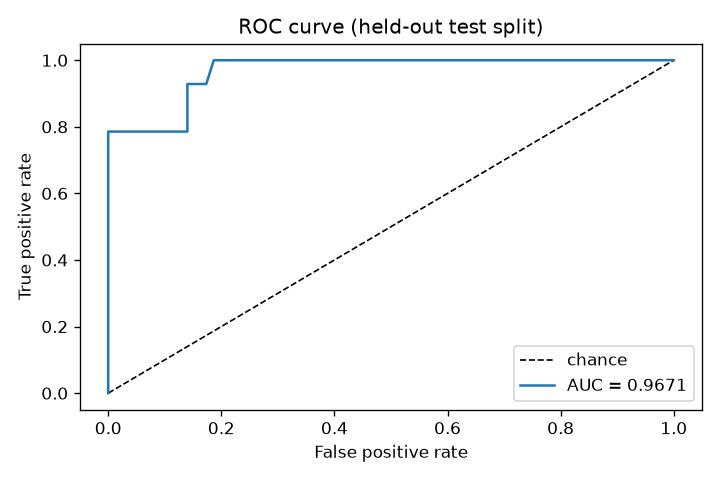

In [7]:
from IPython.display import Image, display

local = client.download_artifacts(result.run_id, "roc.png", "reports")
display(Image(filename=local))

## 3. The gate

`evaluate.auc_threshold` in `params.yaml` is the promotion gate. In CI the
register workflow runs this with `--fail-below-threshold`, so a model that
misses it never reaches the registry.

Treat the threshold as a reviewable decision: changing it is a diff someone
approves, not a number someone edits in a notebook.

In [8]:
Path("reports/evaluation.json").write_text(
    json.dumps(
        {
            "run_id": result.run_id,
            "model_data": handles["model_data"],
            "metrics": result.metrics,
            "threshold": result.threshold,
            "passed": result.passed,
        },
        indent=2,
    ),
    encoding="utf-8",
)
print(Path("reports/evaluation.json").read_text())

{
  "run_id": "0eb9b0c6f641470abae33de9b38e890a",
  "model_data": "s3://sagemaker-us-east-1-063676201336/player-churn/dvc-mlflow/runs/20261028-155311/output/player-churn-xgb-2026-10-28-15-53-18-548/output/model.tar.gz",
  "metrics": {
    "test_auc": 0.9671428571428571,
    "test_average_precision": 0.8641456582633052,
    "test_accuracy": 0.9695121951219512,
    "test_precision": 0.8461538461538461,
    "test_recall": 0.7857142857142857,
    "test_f1": 0.8148148148148148,
    "test_positive_rate": 0.08536585365853659,
    "test_rows": 164.0
  },
  "threshold": 0.75,
  "passed": true
}


In [9]:
print("CLI equivalent (what CI runs):")
print("python -m churn.evaluation --fail-below-threshold")

CLI equivalent (what CI runs):
python -m churn.evaluation --fail-below-threshold


---
## Next

**`05-register.ipynb`** -- register the model in MLflow and mirror it into the
SageMaker Model Registry.

### What changed vs. the original workshop
`model_evaluation/evaluation.py` carried its own copies of
`download_from_s3`/`upload_to_s3`/`read_params`/`write_params` and wrote
`evaluation.json` to S3 by hand. All of that is MLflow's job now. The gate
(`test_score_threshold`) used to exist only inside the CodePipeline template,
invisible from the notebooks; it is in `params.yaml` where you can see it.